# 08 - Étude comparative des représentations textuelles

Le retour d'évaluation demande de **comparer l'approche TF-IDF à d'autres représentations** et de la justifier dans le rapport.
On isole ici l'effet de la représentation : même classifieur (SVM linéaire), même validation croisée (6 plis stratifiés), **texte seul** (`Title` + `Review Text`,
sans `Rating` ni métadonnées) pour que la note ne masque pas les différences.

| # | Représentation | Nature |
|---|----------------|--------|
| R1 | Bag of Words (comptes, unigrammes) | creuse |
| R2 | TF-IDF unigrammes | creuse |
| R3 | TF-IDF unigrammes + bigrammes (**choix actuel du projet**) | creuse |
| R4 | TF-IDF n-grammes de caractères (3-5) | creuse |
| R5 | LSA : TF-IDF (1-2 grammes) réduit à 200 dimensions par SVD tronquée | **dense**, ML classique |
| R6 | Word2Vec moyenné par avis (gensim, entraîné sur le corpus du projet) | **dense** (optionnel) |

Tout reste du **Machine Learning classique** : LSA est une décomposition en valeurs singulières, et Word2Vec n'est utilisé que comme extracteur de variables
pour un SVM (aucun réseau profond, aucun modèle pré-entraîné). Les *Sentence-Transformers* sont volontairement exclus : ce sont des transformeurs pré-entraînés,
incompatibles avec la règle « pas de Deep Learning ni de LLM comme modèle ML » du cahier des charges.

> **Mode rapide** : `DM_FAST=1` réduit les données pour tester le notebook en quelques minutes ; rien n'est sauvegardé dans `reports/`.

In [1]:
import os, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from ml_utils import evaluate_model, get_cv, load_clean_data, split_data, RANDOM_STATE, TITLE, REVIEW

FAST_MODE = os.environ.get("DM_FAST", "0") == "1"
SUB = "fast" if FAST_MODE else ""
FIG_DIR = ROOT / "docs" / "figures" / SUB; REPORT_DIR = ROOT / "reports" / SUB
FIG_DIR.mkdir(parents=True, exist_ok=True); REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean_data()
X_train, X_test, y_train, y_test = split_data(df)
if FAST_MODE:
    from sklearn.model_selection import train_test_split
    X_train, _, y_train, _ = train_test_split(X_train, y_train, train_size=3000, random_state=RANDOM_STATE, stratify=y_train)
    X_test, _, y_test, _ = train_test_split(X_test, y_test, train_size=1000, random_state=RANDOM_STATE, stratify=y_test)

def text_of(X):   # un seul texte par avis : titre + corps
    return (X[TITLE].astype(str) + " . " + X[REVIEW].astype(str)).to_numpy(dtype=object)  # pandas 3 : .values serait un tableau Arrow

T_train, T_test = text_of(X_train), text_of(X_test)
cv = get_cv()
print("Avis d'entraînement :", len(T_train), "| test :", len(T_test), "| CV :", cv.get_n_splits(), "plis")

Avis d'entraînement : 18772 | test : 4693 | CV : 6 plis


## Représentations creuses et LSA

Chaque représentation est placée **dans un `Pipeline`** avec le classifieur : le vocabulaire (et la SVD) sont donc réappris à chaque pli de validation croisée,
sans fuite d'information du pli de validation.

In [2]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.svm import LinearSVC

def clf():
    return LinearSVC(C=0.5, random_state=RANDOM_STATE, max_iter=5000)

mf = 5000 if FAST_MODE else 13000
representations = {
    "R1 Bag of Words (1-gramme)": make_pipeline(CountVectorizer(stop_words="english", max_features=mf), clf()),
    "R2 TF-IDF (1-gramme)": make_pipeline(TfidfVectorizer(stop_words="english", max_features=mf), clf()),
    "R3 TF-IDF (1-2 grammes)": make_pipeline(TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=mf), clf()),
    "R4 TF-IDF caractères (3-5)": make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=mf * 2, sublinear_tf=True), clf()),
    "R5 LSA 200 dim. (dense)": make_pipeline(
        TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=mf),
        TruncatedSVD(n_components=50 if FAST_MODE else 200, random_state=RANDOM_STATE), Normalizer(copy=False), clf()),
}

In [3]:
from sklearn.base import clone

rows = []
fitted = {}
for name, pipe in representations.items():
    t0 = time.time()
    scores = cross_val_score(clone(pipe), T_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    fit_time = time.time() - t0
    model = clone(pipe).fit(T_train, y_train)
    fitted[name] = model
    r = evaluate_model(model, T_test, y_test)
    n_feat = model[0].transform(T_test[:2]).shape[1] if name.startswith(("R1", "R2", "R3", "R4")) else 200
    rows.append({"Représentation": name, "Dimensions": n_feat, "CV F1 macro (moy.)": scores.mean(), "CV F1 macro (écart-type)": scores.std(),
                 "F1 macro (test)": r["F1 macro"], "F1 (0)": r["F1 (0)"], "ROC-AUC": r["ROC-AUC"], "Temps CV (s)": fit_time})
    print(f"{name:<30} CV F1 macro = {scores.mean():.4f} ± {scores.std():.4f} | test F1 macro = {r['F1 macro']:.4f} | AUC = {r['ROC-AUC']:.4f} | {fit_time:.0f}s")

R1 Bag of Words (1-gramme)     CV F1 macro = 0.7914 ± 0.0127 | test F1 macro = 0.7974 | AUC = 0.9027 | 7s
R2 TF-IDF (1-gramme)           CV F1 macro = 0.8124 ± 0.0078 | test F1 macro = 0.8154 | AUC = 0.9313 | 4s
R3 TF-IDF (1-2 grammes)        CV F1 macro = 0.8174 ± 0.0065 | test F1 macro = 0.8192 | AUC = 0.9341 | 5s
R4 TF-IDF caractères (3-5)     CV F1 macro = 0.8265 ± 0.0113 | test F1 macro = 0.8334 | AUC = 0.9431 | 11s
R5 LSA 200 dim. (dense)        CV F1 macro = 0.8085 ± 0.0054 | test F1 macro = 0.8015 | AUC = 0.9289 | 11s


## Word2Vec moyenné (optionnel, nécessite `gensim`)

Un modèle Word2Vec (skip-gram) est entraîné **sur les avis d'entraînement uniquement**, puis chaque avis est représenté par la moyenne des vecteurs de ses mots.
Aucun modèle pré-entraîné n'est téléchargé. L'entraînement est refait à chaque pli pour éviter toute fuite.

In [4]:
try:
    from gensim.models import Word2Vec
    from gensim.utils import simple_preprocess
    from sklearn.base import BaseEstimator, TransformerMixin

    class MeanWord2Vec(BaseEstimator, TransformerMixin):
        def __init__(self, vector_size=100, window=5, min_count=3, epochs=10, seed=RANDOM_STATE):
            self.vector_size, self.window, self.min_count, self.epochs, self.seed = vector_size, window, min_count, epochs, seed
        def fit(self, texts, y=None):
            docs = [simple_preprocess(t) for t in texts]
            self.w2v_ = Word2Vec(docs, vector_size=self.vector_size, window=self.window, min_count=self.min_count,
                                 epochs=self.epochs, workers=1, seed=self.seed, sg=1)
            return self
        def transform(self, texts):
            kv = self.w2v_.wv
            out = np.zeros((len(texts), self.vector_size))
            for i, t in enumerate(texts):
                vecs = [kv[w] for w in simple_preprocess(t) if w in kv]
                if vecs:
                    out[i] = np.mean(vecs, axis=0)
            return out

    from sklearn.preprocessing import StandardScaler
    w2v = make_pipeline(MeanWord2Vec(epochs=5 if FAST_MODE else 10), StandardScaler(), LinearSVC(C=0.1, random_state=RANDOM_STATE, max_iter=5000))
    t0 = time.time()
    scores = cross_val_score(clone(w2v), T_train, y_train, cv=cv, scoring="f1_macro", n_jobs=1)
    fit_time = time.time() - t0
    model = clone(w2v).fit(T_train, y_train); fitted["R6 Word2Vec moyenné (dense)"] = model
    r = evaluate_model(model, T_test, y_test)
    rows.append({"Représentation": "R6 Word2Vec moyenné (dense)", "Dimensions": 100, "CV F1 macro (moy.)": scores.mean(), "CV F1 macro (écart-type)": scores.std(),
                 "F1 macro (test)": r["F1 macro"], "F1 (0)": r["F1 (0)"], "ROC-AUC": r["ROC-AUC"], "Temps CV (s)": fit_time})
    print(f"R6 Word2Vec moyenné : CV F1 macro = {scores.mean():.4f} ± {scores.std():.4f} | test F1 macro = {r['F1 macro']:.4f} | AUC = {r['ROC-AUC']:.4f}")
except ImportError:
    print("gensim n'est pas installé : R6 ignoré (pip install gensim).")

gensim n'est pas installé : R6 ignoré (pip install gensim).


## Synthèse

,Représentation,Dimensions,CV F1 macro (moy.),CV F1 macro (écart-type),F1 macro (test),F1 (0),ROC-AUC,Temps CV (s)
0,R4 TF-IDF caractères (3-5),26000,0.8265,0.0113,0.8334,0.7224,0.9431,10.7318
1,R3 TF-IDF (1-2 grammes),13000,0.8174,0.0065,0.8192,0.6963,0.9341,4.8588
2,R2 TF-IDF (1-gramme),13000,0.8124,0.0078,0.8154,0.6888,0.9313,3.7270
3,R5 LSA 200 dim. (dense),200,0.8085,0.0054,0.8015,0.6653,0.9289,11.0748
4,R1 Bag of Words (1-gramme),13000,0.7914,0.0127,0.7974,0.6624,0.9027,6.8480


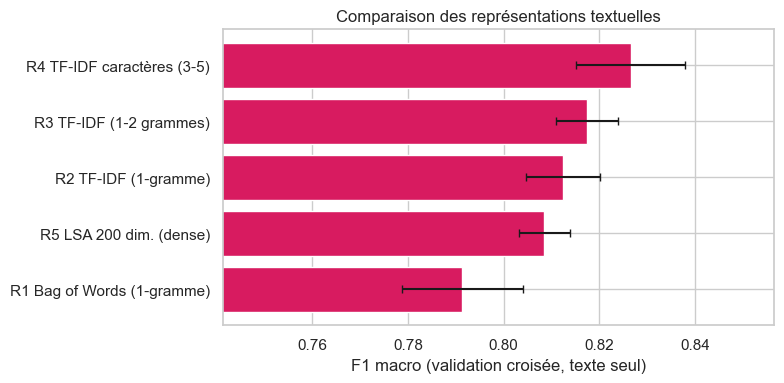

In [5]:
res = pd.DataFrame(rows).sort_values("CV F1 macro (moy.)", ascending=False).reset_index(drop=True)
res.to_csv(REPORT_DIR / "text_representations.csv", index=False)
display(res.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(res["Représentation"], res["CV F1 macro (moy.)"], xerr=res["CV F1 macro (écart-type)"], color="#D81B60", capsize=3)
ax.invert_yaxis(); ax.set_xlabel("F1 macro (validation croisée, texte seul)")
ax.set_xlim(max(0, res["CV F1 macro (moy.)"].min() - 0.05), min(1, res["CV F1 macro (moy.)"].max() + 0.03))
ax.set_title("Comparaison des représentations textuelles")
fig.tight_layout(); fig.savefig(FIG_DIR / "text_representations.png", dpi=200); plt.show()

**À rédiger dans le rapport** : décrire chaque représentation (formule du TF-IDF, rôle des bigrammes, principe de la LSA), le protocole (texte seul, SVM linéaire, 6 plis),
puis commenter le tableau en comparant l'écart entre représentations à l'écart-type de validation croisée avant de conclure qu'une représentation est meilleure.
Si les représentations denses ne font pas mieux que le TF-IDF, c'est un résultat à présenter honnêtement : sur des avis courts et un SVM linéaire, le TF-IDF est une référence solide.